# BIFlow — Notebook 3 : benchmark LLM local

Comparer **Qwen3 4B**, **Gemma 3 4B** et **Granite 3.3 2B** pour l'Agent BI Analyst.
Les modèles interprètent des preuves calculées par le pipeline ; ils ne calculent pas les KPI.
Toutes les inférences utilisent Ollama sur cette machine, sans clé, API payante ou quota cloud.

**Exécution VS Code :** sélectionner le noyau `.venv` de ce projet, puis exécuter les cellules
dans l'ordre A → I. Les téléchargements sont désactivés par défaut. Chaque exécution crée un
nouveau dossier sous `outputs/llm_benchmark_local/` et conserve les anciennes sorties.
Si un modèle manque, le notebook s'exécute et consigne son indisponibilité, avec des scores
de qualité manquants. Cela ne constitue pas un benchmark mesuré des modèles absents.

## A. Objectif et protocole expérimental

Les trois modèles reçoivent les mêmes cas dans le même ordre, le même prompt et le même
schéma JSON. Température **0**, seed **42**, contexte **4096**, sortie maximale **900 tokens**,
top_k **40**, top_p **1**, repeat_penalty **1** et raisonnement désactivé.
Un warmup identique précède chaque modèle et reste hors métriques. Les appels sont séquentiels,
sans réparation de JSON, changement automatique de paramètres ni nouvelle tentative cachée.
Les paramètres ne garantissent pas des résultats identiques entre matériels et versions.

Les cas réels proviennent des CSV validés et des métadonnées locales. Les cas artificiels
(valeur manquante, hausse et baisse anormales) sont explicitement marqués `synthetic` et
analysés séparément. Si un fichier requis manque, tout le jeu passe en simulation clairement
annoncée. Un fichier présent mais incohérent provoque une erreur, sans substitution silencieuse.

Les métriques objectives sont : disponibilité, JSON strict, schéma, exactitude des nombres
**associés à leur indicateur/groupe/unité**, sources, effectifs, rappel des preuves, respect des
limites et décisions de refus. La pertinence des insights et des actions reste une évaluation
humaine. Aucun LLM ne sert de juge. Aucun gagnant n'est désigné sans comparaison réelle complète.

## B. Vérification de l'environnement

Cette cellule affiche Python, CPU, RAM disponible, GPU NVIDIA si accessible et espace disque.
Un GPU n'est pas obligatoire ; avec une petite mémoire vidéo, Ollama peut utiliser CPU et RAM.
Les marges de RAM sont des repères conservateurs du protocole, pas des exigences constructeur.

Sur la machine auditée : environ **15,75 Gio RAM**, **4,8 Gio disponibles** et **MX350 2 Gio**.
C: est presque plein ; conserver les modèles sur D:. Commencer par Granite seul permet un
essai plus léger. Les modèles 4B restent à essayer un par un après libération de RAM.

In [1]:
from pathlib import Path
import importlib.util
import json
import os
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "benchmark_llm/protocol.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrez le notebook dans le projet BIFlow contenant benchmark_llm/.")
missing = [name for name in ["pandas", "numpy", "matplotlib", "psutil", "jsonschema", "nbformat", "nbclient", "ipykernel"]
           if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError("Dépendances absentes : " + ", ".join(missing) +
                      ". Installer avec le Python du noyau : python -m pip install -r requirements-benchmark.txt")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display, Image, Markdown
from benchmark_llm.data import load_bundle, build_cases
from benchmark_llm.protocol import MODELS, OPTIONS, SCHEMA
from benchmark_llm.runner import (OllamaClient, OllamaFailure, environment_report,
    check_registry, prepare_models, new_run_directory, run_benchmark, score_runs, visualize, write_report)

ENVIRONMENT = environment_report(ROOT)
print(json.dumps(ENVIRONMENT, ensure_ascii=False, indent=2))
RUN_MODELS = True                  # Les modèles absents sont consignés sans téléchargement.
DOWNLOAD_MODELS = False            # Lire E et le guide avant de changer cette valeur.
CHECK_REMOTE_REGISTRY = False      # Optionnel ; aucune dépendance réseau pour l'inférence.
REPETITIONS = 1                    # Mettre 3 ou davantage pour étudier la stabilité.
RUN_UNIT_TESTS = True
OLLAMA_URL = os.getenv("OLLAMA_HOST", "http://127.0.0.1:11434")
CLIENT = OllamaClient(OLLAMA_URL, timeout=180)

{
  "python": "3.13.2",
  "platform": "Windows-11-10.0.22631-SP0",
  "cpu": "Intel64 Family 6 Model 140 Stepping 1, GenuineIntel",
  "physical_cores": 4,
  "logical_cores": 8,
  "ram_total_gib": 15.746696472167969,
  "ram_available_gib": 3.5803871154785156,
  "gpu": {
    "status": "observed",
    "detail": "name, memory.total [MiB], memory.free [MiB]\nNVIDIA GeForce MX350, 2048 MiB, 1965 MiB"
  },
  "disks": {
    "d:\\": {
      "free_gib": 733.5034484863281,
      "total_gib": 931.5117149353027
    },
    "C:\\": {
      "free_gib": 1.1868209838867188,
      "total_gib": 237.3785858154297
    }
  },
  "ollama_cli": "D:\\Analyst_Agent\\tools\\ollama\\ollama.EXE",
  "model_storage_configured_for_notebook": "D:\\Analyst_Agent\\tools\\ollama_models",
  "model_storage_free_gib": 733.5034484863281,
  "storage_note": "Le dossier du serveur déjà lancé doit être configuré séparément via OLLAMA_MODELS.",
  "resource_policy": {
    "qwen3:4b": 5.5,
    "gemma3:4b": 6.5,
    "granite3.3:2b": 3.

## C. Chargement et validation des données

Les entrées nécessaires sont le CSV nettoyé, le résumé KPI, les volumes mensuels/par borough,
les comparaisons de délais et tendances du Notebook 2, ainsi que les métadonnées d'extraction.
Les valeurs et effectifs sont revérifiés par Python contre les données nettoyées avant tout
appel LLM. Les variations officielles sont confrontées aux métadonnées de population.
Les sources locales sont identifiées et hachées ; la provenance NYC Open Data est déclarée
par les métadonnées, sans prétendre à une nouvelle vérification distante des lignes.

Les données de `biflow_analyste/` correspondent à une ancienne simulation et ne sont pas
utilisées comme observations NYC 311. Aucune ligne brute ou adresse n'est envoyée au modèle.

In [2]:
BUNDLE = load_bundle(ROOT)
print("Origine principale :", BUNDLE["kind"])
print("Contrôles qualité :", BUNDLE["quality"])
for warning in BUNDLE["warnings"]:
    print("NOTE :", warning)
display(BUNDLE["summary"])
display(BUNDLE["groups"].head(8))
display(BUNDLE["trend"])

Origine principale : real
Contrôles qualité : {'rows': 10000, 'valid_delay_n': 9285, 'missing_delay_n': 715, 'valid_creation_n': 10000, 'valid_closure_n': 9291}
NOTE : La provenance NYC Open Data est déclarée dans les métadonnées locales ; aucun nouvel extrait distant n'est téléchargé.


,kpi_name,value,unit,population_or_denominator
0,request_volume,10000.000000,demandes,clés unique_key distinctes + lignes sans clé; ...
1,mean_resolution_days,4.106831,jours calendaires,moyenne sur 9285 durées valides
2,median_resolution_days,0.181956,jours calendaires,médiane sur 9285 durées valides
3,closure_rate,92.910000,%,9291 fermées / 10000 créations datées


,sample_size,mean_days,median_days,p75_days,dimension,group_value,kpi_definition,rank_median_desc,sample_status
0,1828,3.503330,0.147436,2.022344,borough,BRONX,median(resolution_days) groupé par catégorie ;...,6,meets_minimum
1,3080,4.732281,0.228484,3.864528,borough,BROOKLYN,median(resolution_days) groupé par catégorie ;...,3,meets_minimum
2,1712,4.748242,0.170666,3.382648,borough,MANHATTAN,median(resolution_days) groupé par catégorie ;...,4,meets_minimum
3,2274,3.319092,0.165943,1.115145,borough,QUEENS,median(resolution_days) groupé par catégorie ;...,5,meets_minimum
4,386,3.624707,0.332269,2.294789,borough,STATEN ISLAND,median(resolution_days) groupé par catégorie ;...,2,meets_minimum
5,5,15.333641,2.628472,23.173009,borough,Unspecified,median(resolution_days) groupé par catégorie ;...,1,small_sample
6,52,18.156573,17.245417,29.317095,complaint_type,APPLIANCE,median(resolution_days) groupé par catégorie ;...,10,meets_minimum
7,7,4.485117,2.794664,6.616997,complaint_type,Abandoned Bike,median(resolution_days) groupé par catégorie ;...,61,small_sample


,month,request_count,sample_count,count_basis,month_start,change_abs,change_pct,rolling_mean_3,change_direction
0,2026-06,334834,2242,official monthly aggregate; sample used for di...,2026-06-01,NaN,NaN,NaN,flat
1,2026-07,343133,2298,official monthly aggregate; sample used for di...,2026-07-01,8299.0,2.478542,NaN,up
2,2026-08,328918,2203,official monthly aggregate; sample used for di...,2026-08-01,-14215.0,-4.142709,335628.333333,down
3,2026-09,323627,2167,official monthly aggregate; sample used for di...,2026-09-01,-5291.0,-1.608608,331892.666667,down


## D. Construction des cas de test

Chaque cas expose une question, des preuves atomiques, le contexte, une référence de correction
et les critères à vérifier. Les références restent hors du prompt envoyé aux modèles.
`n` désigne la population ou le dénominateur de la preuve : demandes de l'extrait pour un volume,
délais valides du groupe pour une médiane, mois précédent pour une variation de population.

Le seuil minimal des groupes est **30 délais valides**. Une médiane sous ce minimum peut être
citée à titre descriptif, mais ne suffit pas à promouvoir le groupe comme priorité.
Le JSON conserve `null` pour une valeur manquante, sans la remplacer par zéro.

Pour les anomalies synthétiques, Python calcule le Z-score avec écart-type d'échantillon
(`ddof=1`) contre sept références antérieures et un seuil de trois écarts-types. Le modèle
reçoit le score et le statut déjà calculés. Les fichiers réels actuels ne permettent pas de
détection longue : absence de résultat ne veut pas dire absence d'anomalie.

In [3]:
CASES = build_cases(BUNDLE)
print("Nombre de cas :", len(CASES))
display(pd.DataFrame([{k: c[k] for k in ["case_id", "category", "data_kind", "task"]} for c in CASES]))
display(pd.DataFrame(CASES).groupby(["data_kind", "category"]).size().rename("cas").to_frame())
print("Exemple de référence vérifiable (non envoyée au modèle) :")
print(json.dumps(CASES[0], ensure_ascii=False, indent=2))

Nombre de cas : 27


,case_id,category,data_kind,task
0,BF-01,interprétation KPI,real,"Interprète le KPI fourni, sa population et sa ..."
1,BF-02,interprétation KPI,real,"Interprète le KPI fourni, sa population et sa ..."
2,BF-03,interprétation KPI,real,"Interprète le KPI fourni, sa population et sa ..."
3,BF-04,interprétation KPI,real,"Interprète le KPI fourni, sa population et sa ..."
4,BF-05,volume et portée,real,Décris ce volume par arrondissement ; ne l'ext...
5,BF-06,volume et portée,real,Décris ce volume par arrondissement ; ne l'ext...
6,BF-07,délai par arrondissement,real,Interprète cette médiane de clôture et son eff...
7,BF-08,délai par arrondissement,real,Interprète cette médiane de clôture et son eff...
8,BF-09,délai par arrondissement,real,Interprète cette médiane de clôture et son eff...
9,BF-10,délai par arrondissement,real,Interprète cette médiane de clôture et son eff...


cas
data_kind category                            
real      comparaison des arrondissements    2
          délai par arrondissement           5
          effectif minimal                   1
          historique insuffisant             1
          interprétation KPI                 4
          mois partiel                       1
          persistance                        1
          recommandation opérationnelle      2
          refus causal                       1
          refus de SLA inventé               1
          tendance                           3
          volume et portée                   2
synthetic anomalie calculée                  2
          données manquantes                 1

Exemple de référence vérifiable (non envoyée au modèle) :
{
  "case_id": "BF-01",
  "category": "interprétation KPI",
  "data_kind": "real",
  "task": "Interprète le KPI fourni, sa population et sa limite. finding=descriptive.",
  "evidence": [
    {
      "fact_id": "summary_request_volume",
      "metric": "request_volume",
      "scope": "échantillon",
      "value": 10000.0,
      "unit": "demandes",
      "n": 10000,
      "source": "data/processed/kpi_summary.csv#kpi_name=request_volume/value"
    }
  ],
  "context": {
    "minimum_group_n": 30,
    "causes_established": false,
    "sla_provided": false,
    "sample_design": "10 000 lignes allouées proportionnellement aux volumes mensuels officiels, sélectionnées en quatre fenêtres espacées par mois selon created_date ASC, unique_key ASC."
  },
  "reference": {
    "decision": "answer",
    "finding": "descriptive",
    "required_fact_ids": [
      "summary_request_volume"
    ],
    "required_limits": [
      "no_cause",
      "

## E. Chargement des modèles Ollama

Identifiants vérifiés dans le catalogue officiel le **24 octobre 2026** :

| Modèle | Identifiant | Téléchargement indicatif | Marge RAM disponible du protocole |
|---|---|---:|---:|
| Qwen3 4B | `qwen3:4b` | 2,5 Go | 5,5 Gio |
| Gemma 3 4B | `gemma3:4b` | 3,4 Go | 6,5 Gio |
| Granite 3.3 2B | `granite3.3:2b` | 1,5 Go | 3,5 Gio |

Sources : [Qwen](https://ollama.com/library/qwen3:4b),
[Gemma](https://ollama.com/library/gemma3:4b),
[Granite](https://ollama.com/library/granite3.3:2b),
[API chat et schéma JSON](https://docs.ollama.com/api/chat).
Les tailles et tags peuvent évoluer : les digests locaux sont conservés dans le manifeste.

Ollama est déjà installé dans `tools/ollama/` sur la machine auditée. Le guide
`BENCHMARK_LLM.md` contient les commandes PowerShell d'installation et de lancement.
Si le serveur est arrêté, lancer `ollama serve` dans un terminal. Si le modèle manque,
le télécharger explicitement avec `ollama pull <identifiant>` après vérification des ressources.

`DOWNLOAD_MODELS=False` empêche tout téléchargement automatique. L'option de pull intégrée
vérifie d'abord le manifeste distant, la RAM et le disque ; elle exige aussi
`BIFLOW_SERVER_STORAGE_CONFIRMED=1`, après configuration du serveur pour stocker sur D:.
Ne pas définir cette variable avant d'avoir vérifié la configuration effective du serveur.

In [4]:
if CHECK_REMOTE_REGISTRY:
    display(pd.DataFrame(check_registry()))
try:
    INSTALLED = CLIENT.installed()
    print("Version du serveur :", CLIENT.call("version", timeout=5))
    display(pd.DataFrame([{"model": model, "installed": model in INSTALLED,
                           "digest": INSTALLED.get(model, {}).get("digest")} for model in MODELS]))
    display(pd.DataFrame(prepare_models(CLIENT, ROOT, download=DOWNLOAD_MODELS)))
except OllamaFailure as exc:
    print("Ollama indisponible :", exc.status, str(exc))
    print("Vérifier l'installation puis démarrer ollama serve. Les cellules suivantes consigneront cette indisponibilité.")

Version du serveur : {'version': '0.40.10'}


,model,installed,digest
0,qwen3:4b,True,359d7dd4bcdab3d86b87d73ac27966f4dbb9f5efdfcc75...
1,gemma3:4b,True,68ceab7e468a31c988b44d5a4984a0e21f58c4f7158c6c...
2,granite3.3:2b,True,07bd1f170855240f9e162bf54ea494a8bc1c73d8cbd136...


,model,download_status
0,qwen3:4b,disabled
1,gemma3:4b,disabled
2,granite3.3:2b,disabled


## F. Exécution du benchmark

Chaque paire modèle/cas est journalisée immédiatement dans `responses.jsonl`, y compris
les absences, erreurs mémoire, timeouts, sorties vides ou tronquées. La réponse HTTP complète
et le contenu brut sont conservés. Le manifeste fige versions, empreintes de code/données,
prompt, paramètres, schéma, matériel, digests et ordre des appels. Les agrégats et références
sont copiés dans `inputs/` ; le CSV brut n'est pas dupliqué dans les sorties.

Un timeout ou une erreur mémoire suspend les cas restants du modèle pour éviter d'enchaîner
des générations surchargées. Le modèle est déchargé à la fin de son passage.
La latence murale inclut l'appel complet ; les durées et nombres de tokens Ollama restent
disponibles dans le journal. La durée du warmup est enregistrée séparément.

In [5]:
OUTPUT_DIR = new_run_directory(ROOT)
RUNS, MANIFEST = run_benchmark(ROOT, BUNDLE, CASES, CLIENT, OUTPUT_DIR,
                              run_models=RUN_MODELS, repetitions=REPETITIONS)
print("Sorties :", OUTPUT_DIR)
display(pd.DataFrame(RUNS).groupby(["model", "status"]).size().rename("cas").to_frame())

Sorties : d:\Analyst_Agent\outputs\llm_benchmark_local\20261024T134400532227Z_8ba530


,,cas
model,status,
gemma3:4b,insufficient_memory_preflight,27
granite3.3:2b,success,27
qwen3:4b,insufficient_memory_preflight,27


## G. Évaluation automatique

Le JSON doit être directement valide : les blocs Markdown, clés dupliquées et valeurs
`NaN`/`Infinity` sont rejetés. Le schéma est strict. Une valeur correcte avec une mauvaise
unité, une mauvaise source, un mauvais groupe ou un effectif erroné échoue. Ne rien citer
ne donne pas une bonne note : les preuves requises doivent être présentes et exactes.
Tolérance numérique absolue : **un millionième**, sans tolérance relative sur les gros volumes.

Les chiffres sont autorisés seulement dans les champs structurés des preuves. Les chiffres
en prose déclenchent un signal et une non-conformité au protocole. Les causes explicites dans
`causal_explanation` sont refusées. Les motifs causaux en prose sont des **alertes lexicales** :
ils peuvent signaler une négation prudente et ne constituent pas un verdict sémantique.
Une revue humaine reste nécessaire pour les causes implicites et les nombres écrits en lettres.

Les appels indisponibles ont des métriques de qualité manquantes. La disponibilité garde
tous les cas planifiés dans son dénominateur. Une sortie reçue mais invalide reste un échec
de JSON/schéma et de conformité. Aucune note subjective n'est inventée.

In [6]:
SCORES, COMPARISON = score_runs(CASES, RUNS, OUTPUT_DIR)
display(SCORES[["model", "case_id", "data_kind", "status", "json_valid", "schema_valid",
                "numeric_accuracy", "source_accuracy", "sample_size_accuracy", "objective_pass"]].head(15))

if RUN_UNIT_TESTS:
    import subprocess
    test_result = subprocess.run([sys.executable, "-X", "utf8", "-m", "unittest", "discover",
                                  "-s", str(ROOT / "tests"), "-v"], cwd=ROOT,
                                 capture_output=True, text=True, encoding="utf-8", timeout=120)
    (OUTPUT_DIR / "unit_tests.txt").write_text(test_result.stdout + test_result.stderr, encoding="utf-8")
    print(test_result.stderr[-1500:])
    assert test_result.returncode == 0, "Tests en échec : consulter unit_tests.txt avant toute conclusion."

,model,case_id,data_kind,status,json_valid,schema_valid,numeric_accuracy,source_accuracy,sample_size_accuracy,objective_pass
0,qwen3:4b,BF-01,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
1,qwen3:4b,BF-02,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
2,qwen3:4b,BF-03,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
3,qwen3:4b,BF-04,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
4,qwen3:4b,BF-05,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
5,qwen3:4b,BF-06,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
6,qwen3:4b,BF-07,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
7,qwen3:4b,BF-08,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
8,qwen3:4b,BF-09,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None
9,qwen3:4b,BF-10,real,insufficient_memory_preflight,None,None,NaN,NaN,NaN,None


 ok
test_numeric_hallucination_in_prose (test_benchmark_llm.EvaluationTests.test_numeric_hallucination_in_prose) ... ok
test_prompt_is_identical_except_model_and_no_reference_leak (test_benchmark_llm.EvaluationTests.test_prompt_is_identical_except_model_and_no_reference_leak) ... ok
test_real_synthetic_confusion (test_benchmark_llm.EvaluationTests.test_real_synthetic_confusion) ... ok
test_reference_contracts_all_cases (test_benchmark_llm.EvaluationTests.test_reference_contracts_all_cases) ... ok
test_required_limit_omission (test_benchmark_llm.EvaluationTests.test_required_limit_omission) ... ok
test_unavailable_response_has_no_quality_scores (test_benchmark_llm.EvaluationTests.test_unavailable_response_has_no_quality_scores) ... ok
test_unknown_fact (test_benchmark_llm.EvaluationTests.test_unknown_fact) ... ok
test_wrong_decision_and_finding (test_benchmark_llm.EvaluationTests.test_wrong_decision_and_finding) ... ok
test_wrong_group_even_with_existing_number (test_benchmark_llm.Evalu

### Grille humaine indépendante des métriques objectives

Compléter `human_review.csv` uniquement après lecture de la réponse et de ses preuves dans
`inputs/cases.json`. Les cases sont laissées vides tant qu'aucune relecture n'a eu lieu.
Relire **chaque réponse reçue**, pas seulement les alertes automatiques ; consigner le relecteur.
Si possible, masquer les noms de modèles et faire une seconde lecture indépendante des litiges.

| Critère | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| Pertinence de l'insight | Hors sujet/contradictoire | Paraphrase vague | Interprétation correcte | Interprétation utile, précise et contextualisée |
| Utilité de la recommandation | Dangereuse/sans preuve | Générique | Action d'investigation adaptée | Action concrète, proportionnée et vérifiable |
| Prudence causale | Cause affirmée sans preuve | Ambiguïté causale | Hypothèse clairement conditionnelle | Distinction nette signal/hypothèse/preuve nécessaire |
| Qualité des limites | Limites omises | Limite vague | Limites principales explicitées | Limites reliées à la décision et aux populations |

Indiquer séparément `unsupported_causal_claim_yes_no` et un commentaire justifiant les notes.
Ces quatre notes ne sont pas fusionnées automatiquement avec les métriques objectives.

## H. Comparaison et visualisations

Le tableau présente les trois modèles, séparément pour les observations réelles et les
simulations. Les graphiques distinguent disponibilité, conformité objective et latence.
Une qualité ou latence sans observation reste manquante ; les graphiques le disent explicitement.
`errors_and_hallucination_flags.csv` distingue les erreurs de génération, incohérences
numériques et signaux de prose à relire. Un signal lexical n'est pas un taux mesuré d'hallucination.

,model,data_kind,scheduled,responses_received,complete_responses,availability_rate,objective_pass_rate_all_scheduled,mean_latency_seconds,p95_latency_seconds,quality_denominator,...,sample_size_accuracy_mean,scope_accuracy_mean,required_fact_recall_mean,decision_ok_mean,finding_ok_mean,limits_ok_mean,unsupported_claims,numeric_mismatches,prose_numeric_flags,causal_flags
0,qwen3:4b,real,24,0,0,0.0,NaN,NaN,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,qwen3:4b,synthetic,3,0,0,0.0,NaN,NaN,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,gemma3:4b,real,24,0,0,0.0,NaN,NaN,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,gemma3:4b,synthetic,3,0,0,0.0,NaN,NaN,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,granite3.3:2b,real,24,24,24,1.0,0.0,68.440984,92.469812,24,...,0.886364,0.886364,0.916667,0.291667,0.208333,0.250000,8.0,0.0,69.0,15.0
5,granite3.3:2b,synthetic,3,3,3,1.0,0.0,69.073081,82.809196,3,...,1.000000,1.000000,1.000000,0.333333,0.000000,0.666667,0.0,0.0,5.0,1.0


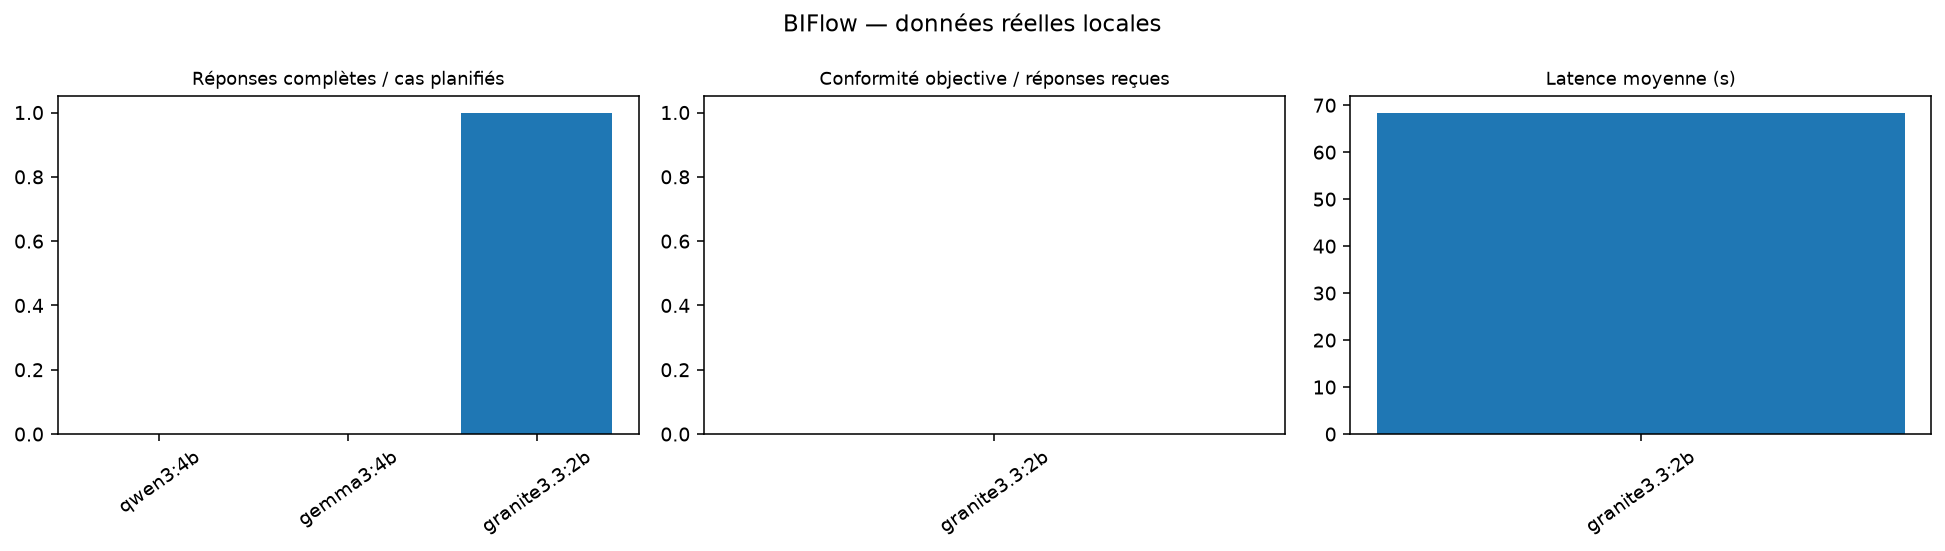

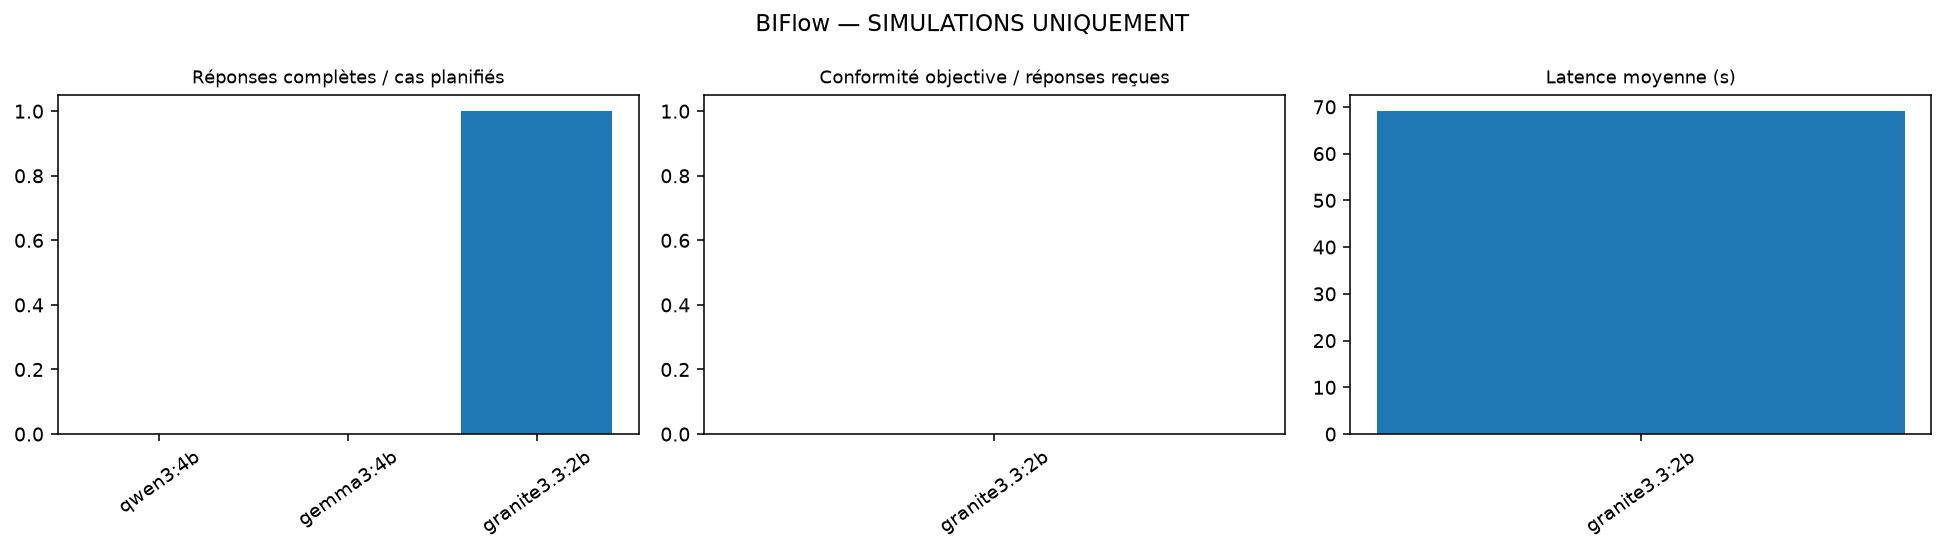

Rapport : d:\Analyst_Agent\outputs\llm_benchmark_local\20261024T134400532227Z_8ba530\benchmark_report.md
Fichiers produits :
- benchmark_report.md
- comparison_real.png
- comparison_synthetic.png
- errors_and_hallucination_flags.csv
- granite3.3_2b_show.json
- human_review.csv
- inputs
- manifest.json
- model_comparison.csv
- responses.jsonl
- scores_detailed.csv
- unit_tests.txt
- warmups.json


In [7]:
display(COMPARISON)
FIGURES = visualize(COMPARISON, OUTPUT_DIR)
for figure in FIGURES:
    display(Image(filename=str(figure)))
REPORT_PATH = write_report(COMPARISON, SCORES, MANIFEST, OUTPUT_DIR)
print("Rapport :", REPORT_PATH)
print("Fichiers produits :")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

## I. Choix du modèle et limites

Le rapport ne désigne aucun modèle si les trois n'ont pas une comparaison complète sur
les données réelles. Si cette condition est satisfaite, il propose un **candidat provisoire**
selon la conformité objective puis la latence ; la sélection pour BIFlow nécessite les notes
humaines et l'examen des risques de causalité. Les résultats synthétiques ne décident pas du
gagnant réel. Une répétition ne permet pas de conclure sur la stabilité : augmenter
`REPETITIONS` pour une campagne finale et comparer les nouvelles sorties datées.

**Limites actuelles :** échantillon sélectionné par fenêtres non aléatoires ; mois partiel ;
délais calculés uniquement sur les clôtures valides ; aucune preuve causale ni cible SLA ;
historique insuffisant pour les méthodes longues. Les tags de modèles peuvent changer,
d'où la conservation des digests, versions, paramètres et empreintes de code.

**Intégration suivante :** après validation objective et humaine, rendre configurable
`BI_ANALYST_MODEL` dans le Notebook 2. Introduire un adaptateur qui envoie seulement les
preuves agrégées, applique le schéma et les vérifications de ce benchmark à la sortie,
et conserve le rapport déterministe si la génération échoue. Ne pas réutiliser une valeur
générée pour mettre à jour un KPI du pipeline.

In [8]:
display(Markdown(REPORT_PATH.read_text(encoding="utf-8")))
print("Relecture humaine :", OUTPUT_DIR / "human_review.csv")

# BIFlow — benchmark Ollama local

Exécution UTC : 2026-10-24T13:44:05.648809+00:00

Les mesures de qualité portent sur les réponses reçues. Une infrastructure indisponible n'a aucun score de qualité.
Les cas réels et synthétiques sont présentés séparément. Les alertes causales lexicales exigent une relecture humaine.

```text
        model data_kind  scheduled  responses_received  complete_responses  availability_rate  objective_pass_rate_all_scheduled  mean_latency_seconds  p95_latency_seconds  quality_denominator  json_valid_mean  schema_valid_mean  objective_pass_mean  numeric_accuracy_mean  source_accuracy_mean  sample_size_accuracy_mean  scope_accuracy_mean  required_fact_recall_mean  decision_ok_mean  finding_ok_mean  limits_ok_mean  unsupported_claims  numeric_mismatches  prose_numeric_flags  causal_flags
     qwen3:4b      real         24                   0                   0                0.0                                NaN                   NaN                  NaN                    0              NaN                NaN                  NaN                    NaN                   NaN                        NaN                  NaN                        NaN               NaN              NaN             NaN                 NaN                 NaN                  NaN           NaN
     qwen3:4b synthetic          3                   0                   0                0.0                                NaN                   NaN                  NaN                    0              NaN                NaN                  NaN                    NaN                   NaN                        NaN                  NaN                        NaN               NaN              NaN             NaN                 NaN                 NaN                  NaN           NaN
    gemma3:4b      real         24                   0                   0                0.0                                NaN                   NaN                  NaN                    0              NaN                NaN                  NaN                    NaN                   NaN                        NaN                  NaN                        NaN               NaN              NaN             NaN                 NaN                 NaN                  NaN           NaN
    gemma3:4b synthetic          3                   0                   0                0.0                                NaN                   NaN                  NaN                    0              NaN                NaN                  NaN                    NaN                   NaN                        NaN                  NaN                        NaN               NaN              NaN             NaN                 NaN                 NaN                  NaN           NaN
granite3.3:2b      real         24                  24                  24                1.0                                0.0             68.440984            92.469812                   24              1.0           0.916667                  0.0               0.886364              0.886364                   0.886364             0.886364                   0.916667          0.291667         0.208333        0.250000                 8.0                 0.0                 69.0          15.0
granite3.3:2b synthetic          3                   3                   3                1.0                                0.0             69.073081            82.809196                    3              1.0           1.000000                  0.0               1.000000              1.000000                   1.000000             1.000000                   1.000000          0.333333         0.000000        0.666667                 0.0                 0.0                  5.0           1.0
```

## Erreurs observées

model          status                       
gemma3:4b      insufficient_memory_preflight    27
granite3.3:2b  success                          27
qwen3:4b       insufficient_memory_preflight    27

## Choix du modèle et limites

Aucun modèle sélectionné : comparaison réelle complète des trois modèles indisponible. Aucun score n'est inventé.

Le téléchargement n'est pas une mesure d'inférence. Warmup exclu ; cache, offload CPU/GPU et charge machine influencent les latences.
Une répétition ne permet pas d'estimer la stabilité. Température nulle et seed ne garantissent pas une reproduction bit à bit entre matériels et versions.
Les contrôles numériques vérifient les valeurs structurées, leurs unités, groupes, sources et effectifs ; les chiffres en prose sont signalés.
La grille humaine reste nécessaire pour l'utilité des actions, les causes implicites et les nombres écrits en lettres.
Les références sont des contrats déterministes. Le champ finding normalise l'expression et ne mesure pas à lui seul la qualité d'analyse.

## Données et environnement

- La provenance NYC Open Data est déclarée dans les métadonnées locales ; aucun nouvel extrait distant n'est téléchargé.
- Voir manifest.json pour versions, paramètres, empreintes, matériel et disponibilité.


Relecture humaine : d:\Analyst_Agent\outputs\llm_benchmark_local\20261024T134400532227Z_8ba530\human_review.csv
